# 📘 Week 7 Practical and Revision Workbook

## Numerical Differentiation and Ordinary Differential Equations

This workbook connects Notes 7.1–7.5 through runnable engineering activities. Begin the
guided A activities in Monday's workshop, continue the B problems during Wednesday's
practical, and finish the revision section at home.


# 🧭 Weekly workflow and expected effort

| Stage | Suggested use | Approximate time |
|---|---|---:|
| Before Monday | Run Notes 7.1–7.5 and record questions | 2 hours |
| Monday workshop | Guided Activities 1A–5A, demonstrations and discussion | 2 hours |
| Wednesday practical | Problem-solving Activities 1B–5B with tutor support | 2 hours |
| Revision | Finish problems and complete Activities 6–7 | 3 hours |

Every activity follows **Predict → Change or select → Run → Inspect → Explain →
Validate**. Monday does not require every A activity to be completed in full.


# 🧩 How the A and B activities work

- **A activities are guided explorations.** Change the marked `TODO` values, run the cell,
  and explain the behaviour visible in the figure.
- **B activities are problems to solve.** All datasets, candidate settings and functions
  are supplied. The starter choice runs, but it is not necessarily defensible.
- Each B problem includes progressive hints and a visualisation of the current selection.
- A strong answer reports units, evidence, assumptions and limitations—not only a method
  name or number.
- Activities **6 and 7+** are revision and integration tasks. They are intentionally less
  scaffolded and are useful preparation for later assessment.


# 🎯 Learning objectives

By completing this workbook, you should be able to:

- estimate derivatives from uniform and irregular sampled coordinates;
- explain how resolution, boundaries and noise affect numerical differentiation;
- define ODE states, parameters, inputs, outputs and initial conditions;
- connect experimental data to parameter calibration and independent validation;
- implement Euler, midpoint RK2 and classical RK4 time marching;
- choose a time step or solver using stability, accuracy and computational evidence;
- convert a higher-order ODE into a coupled first-order state system; and
- distinguish measurement samples from a solver's internal time steps.


# 📚 Week 7 notes map

| Workbook pair | Supporting notes | Main skill |
|---|---|---|
| 1A–1B | 7.1 Finite-Difference Derivatives | Coordinates, noise and derivative evidence |
| 2A–2B | 7.2 ODEs and Initial-Value Problems | States, parameters, calibration and validation |
| 3A–3B | 7.3 Euler's Method | Step size, convergence and stability |
| 4A–4B | 7.4 Runge–Kutta Methods | Accuracy per function evaluation and adaptive solving |
| 5A–5B | 7.5 Higher-Order ODEs | State conversion, damping and measured outputs |


# 🧰 Shared setup

Run these cells before beginning any activity. They define deterministic teaching models
and numerical tools. The generated signals are not certified equipment data.


In [ ]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.signal import savgol_filter

pd.set_option("display.precision", 6)
plt.rcParams["figure.figsize"] = (8.5, 5.0)


def actuator_position_m(time_s):
    time_s = np.asarray(time_s, dtype=float)
    return 0.018 * np.sin(1.35*time_s) + 0.004 * np.sin(3.8*time_s + 0.25)


def actuator_velocity_m_s(time_s):
    time_s = np.asarray(time_s, dtype=float)
    return 0.018*1.35*np.cos(1.35*time_s) + 0.004*3.8*np.cos(3.8*time_s + 0.25)


def thermal_rhs(t, temperature_C, heat_capacity_J_K, loss_W_K,
                ambient_C=22.0, heater_W=45.0):
    return (heater_W - loss_W_K*(temperature_C - ambient_C)) / heat_capacity_J_K


def exact_thermal_temperature(time_s, initial_C, heat_capacity_J_K,
                              loss_W_K, ambient_C=22.0, heater_W=45.0):
    time_s = np.asarray(time_s, dtype=float)
    equilibrium_C = ambient_C + heater_W/loss_W_K
    return equilibrium_C + (initial_C-equilibrium_C)*np.exp(
        -loss_W_K*time_s/heat_capacity_J_K
    )


def fixed_step_scalar(rhs, t_span, initial_value, step_s, method):
    t0, tf = t_span
    steps = int(np.ceil((tf-t0)/step_s))
    times = np.linspace(t0, tf, steps+1)
    values = np.empty(steps+1)
    values[0] = initial_value
    evaluations = 0
    for index in range(steps):
        t = times[index]
        h = times[index+1]-t
        y = values[index]
        k1 = rhs(t, y)
        if method == "euler":
            values[index+1] = y + h*k1
            evaluations += 1
        elif method == "rk2":
            k2 = rhs(t+h/2, y+h*k1/2)
            values[index+1] = y + h*k2
            evaluations += 2
        elif method == "rk4":
            k2 = rhs(t+h/2, y+h*k1/2)
            k3 = rhs(t+h/2, y+h*k2/2)
            k4 = rhs(t+h, y+h*k3)
            values[index+1] = y + h*(k1+2*k2+2*k3+k4)/6
            evaluations += 4
        else:
            raise ValueError("method must be 'euler', 'rk2' or 'rk4'")
    return times, values, evaluations


def oscillator_rhs(t, state, mass_kg, damping_Ns_m, stiffness_N_m,
                   force_amplitude_N=0.0, force_frequency_rad_s=0.0):
    position_m, velocity_m_s = state
    force_N = force_amplitude_N*np.sin(force_frequency_rad_s*t)
    acceleration_m_s2 = (
        force_N - damping_Ns_m*velocity_m_s - stiffness_N_m*position_m
    ) / mass_kg
    return [velocity_m_s, acceleration_m_s2]


# 🟧 Monday workshop — guided exploration

Activities 1A–5A contain valid `TODO` values. Change one value at a time, predict the
effect before running, and record what the figure or table shows.


## Activity 1A — Sampling, noise and a velocity estimate

A displacement sensor observes a moving actuator. Change `TODO_SAMPLE_COUNT_1A` among
`21`, `41`, `81` and `161`; change `TODO_NOISE_MM_1A` among `0`, `0.05`, `0.20` and
`0.50`; and compare `"gradient"` with `"smoothed"`.

**Predict first:** will more samples always improve a derivative when measurement noise is
present? What trade-off does smoothing introduce?




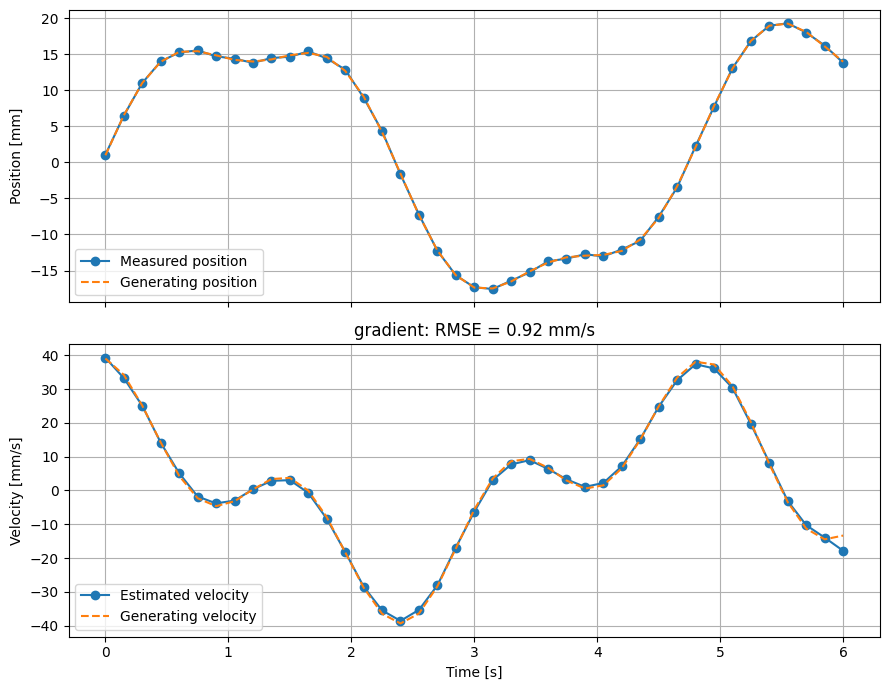

In [ ]:
TODO_SAMPLE_COUNT_1A = 41       # TODO: try 21, 41, 81 and 161
TODO_NOISE_MM_1A = 0.20         # TODO: try 0, 0.05, 0.20 and 0.50
TODO_METHOD_1A = "gradient"     # TODO: use "gradient" or "smoothed"

time_1a = np.linspace(0.0, 6.0, TODO_SAMPLE_COUNT_1A)
deterministic_noise_1a = (TODO_NOISE_MM_1A/1000)*np.sin(19.7*time_1a + 0.4)
measured_position_1a = actuator_position_m(time_1a) + deterministic_noise_1a
if TODO_METHOD_1A == "gradient":
    velocity_1a = np.gradient(measured_position_1a, time_1a, edge_order=2)
elif TODO_METHOD_1A == "smoothed":
    window_1a = min(11, TODO_SAMPLE_COUNT_1A if TODO_SAMPLE_COUNT_1A % 2 else TODO_SAMPLE_COUNT_1A-1)
    velocity_1a = savgol_filter(measured_position_1a, window_1a, 3, deriv=1,
                                delta=time_1a[1]-time_1a[0])
else:
    raise ValueError("TODO_METHOD_1A must be 'gradient' or 'smoothed'")

exact_velocity_1a = actuator_velocity_m_s(time_1a)
rmse_1a = np.sqrt(np.mean((velocity_1a-exact_velocity_1a)**2))
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
axes[0].plot(time_1a, 1000*measured_position_1a, "o-", label="Measured position")
axes[0].plot(time_1a, 1000*actuator_position_m(time_1a), "--", label="Generating position")
axes[0].set(ylabel="Position [mm]"); axes[0].grid(True); axes[0].legend()
axes[1].plot(time_1a, 1000*velocity_1a, "o-", label="Estimated velocity")
axes[1].plot(time_1a, 1000*exact_velocity_1a, "--", label="Generating velocity")
axes[1].set(xlabel="Time [s]", ylabel="Velocity [mm/s]",
            title=f"{TODO_METHOD_1A}: RMSE = {1000*rmse_1a:.2f} mm/s")
axes[1].grid(True); axes[1].legend(); fig.tight_layout(); plt.show()


## Activity 2A — What an ODE parameter changes

The state is temperature $T(t)$. The heat capacity $C$ controls thermal inertia; the heat-
loss coefficient $H$ controls both response time and equilibrium temperature. Change the
two `TODO` values and inspect the response.



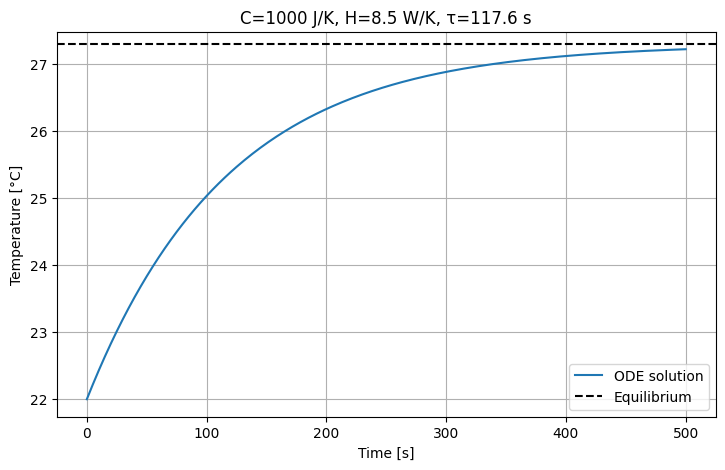

In [ ]:
TODO_CAPACITY_2A = 1000.0    # TODO: try 250, 520 and 1000 J/K
TODO_LOSS_2A = 8.5          # TODO: try 2.5, 4.5 and 8.0 W/K

time_2a = np.linspace(0.0, 500.0, 301)
temperature_2a = exact_thermal_temperature(time_2a, 22.0, TODO_CAPACITY_2A, TODO_LOSS_2A)
equilibrium_2a = 22.0 + 45.0/TODO_LOSS_2A
time_constant_2a = TODO_CAPACITY_2A/TODO_LOSS_2A
plt.plot(time_2a, temperature_2a, label="ODE solution")
plt.axhline(equilibrium_2a, linestyle="--", color="black", label="Equilibrium")
plt.xlabel("Time [s]"); plt.ylabel("Temperature [°C]")
plt.title(f"C={TODO_CAPACITY_2A:g} J/K, H={TODO_LOSS_2A:g} W/K, τ={time_constant_2a:.1f} s")
plt.grid(True); plt.legend(); plt.show()


## Activity 3A — Euler step size and stability

Euler's method advances from one numerical state to the next using the current slope.
Change `TODO_STEP_3A` among `5`, `25`, `75`, `140` and `260` seconds.

**Predict first:** which values produce a smooth approximation, alternating errors, or an
unstable response? Compare the dimensionless factor $1-hH/C$ with the condition
$|1-hH/C|<1$.





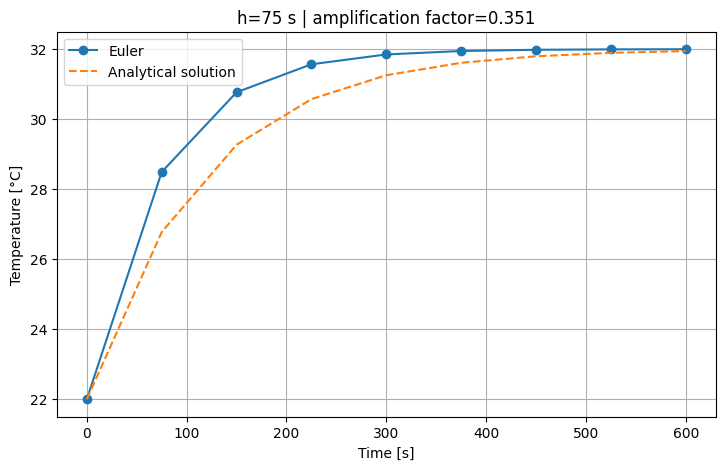

Linear stability condition satisfied: True


In [ ]:
TODO_STEP_3A = 75.0  # TODO: try 5, 25, 75, 140 and 260 s
C_3a, H_3a = 520.0, 4.5
rhs_3a = lambda t, T: thermal_rhs(t, T, C_3a, H_3a)
time_3a, euler_3a, _ = fixed_step_scalar(rhs_3a, (0.0, 600.0), 22.0, TODO_STEP_3A, "euler")
exact_3a = exact_thermal_temperature(time_3a, 22.0, C_3a, H_3a)
amplification_3a = 1-TODO_STEP_3A*H_3a/C_3a
plt.plot(time_3a, euler_3a, "o-", label="Euler")
plt.plot(time_3a, exact_3a, "--", label="Analytical solution")
plt.xlabel("Time [s]"); plt.ylabel("Temperature [°C]")
plt.title(f"h={TODO_STEP_3A:g} s | amplification factor={amplification_3a:.3f}")
plt.grid(True); plt.legend(); plt.show()
print("Linear stability condition satisfied:", abs(amplification_3a) < 1)


## Activity 4A — Accuracy versus right-hand-side evaluations

Compare `"euler"`, `"rk2"` and `"rk4"`, then change the fixed step. Higher-order stages
cost more per step, so compare both error and the number of evaluations.




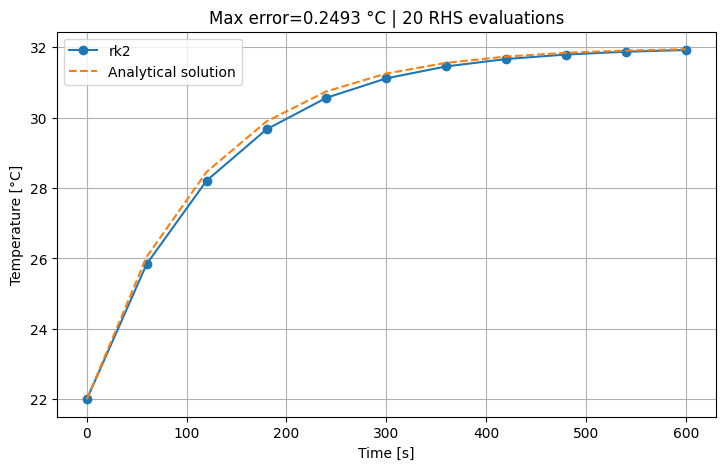

In [ ]:
TODO_METHOD_4A = "rk2"  # TODO: use "euler", "rk2" or "rk4"
TODO_STEP_4A = 60.0      # TODO: try 15, 30, 60 and 120 s
C_4a, H_4a = 520.0, 4.5
rhs_4a = lambda t, T: thermal_rhs(t, T, C_4a, H_4a)
time_4a, temperature_4a, evaluations_4a = fixed_step_scalar(
    rhs_4a, (0.0, 600.0), 22.0, TODO_STEP_4A, TODO_METHOD_4A
)
exact_4a = exact_thermal_temperature(time_4a, 22.0, C_4a, H_4a)
max_error_4a = np.max(np.abs(temperature_4a-exact_4a))
plt.plot(time_4a, temperature_4a, "o-", label=TODO_METHOD_4A)
plt.plot(time_4a, exact_4a, "--", label="Analytical solution")
plt.xlabel("Time [s]"); plt.ylabel("Temperature [°C]")
plt.title(f"Max error={max_error_4a:.4f} °C | {evaluations_4a} RHS evaluations")
plt.grid(True); plt.legend(); plt.show()


## Activity 5A — Damping in a second-order system

For $m\ddot{x}+c\dot{x}+kx=0$, the two first-order states are position $x$ and velocity
$v=\dot{x}$. Change the damping ratio and initial velocity. The code converts
$c=2\zeta\sqrt{km}$ before solving the coupled state equations.



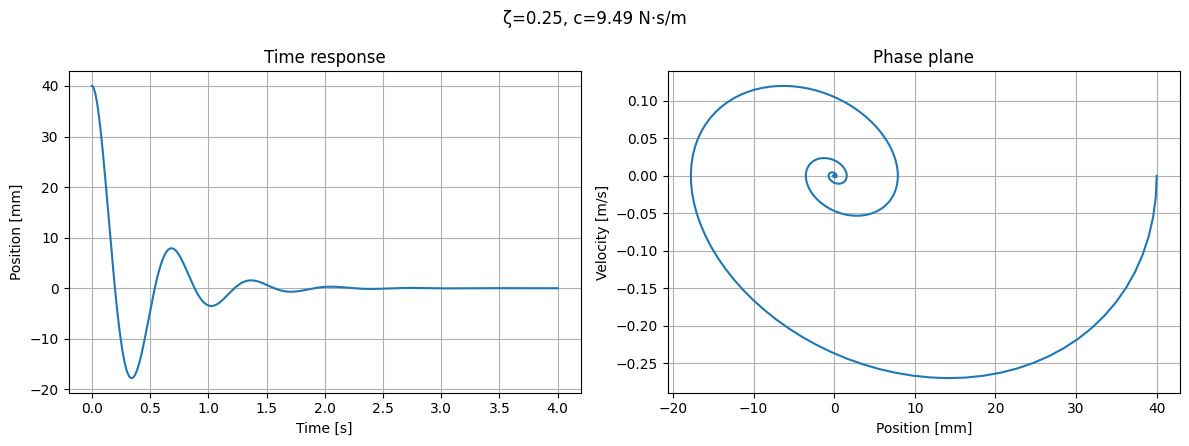

In [ ]:
TODO_DAMPING_RATIO_5A = 0.25  # TODO: try 0.0, 0.15, 1.0 and 1.5
TODO_INITIAL_VELOCITY_5A = 0.0  # TODO: try -0.25, 0.0 and 0.25 m/s
mass_5a, stiffness_5a = 2.0, 180.0
damping_5a = 2*TODO_DAMPING_RATIO_5A*np.sqrt(mass_5a*stiffness_5a)
time_5a = np.linspace(0.0, 4.0, 501)
solution_5a = solve_ivp(
    lambda t, y: oscillator_rhs(t, y, mass_5a, damping_5a, stiffness_5a),
    (time_5a[0], time_5a[-1]), [0.04, TODO_INITIAL_VELOCITY_5A], t_eval=time_5a,
    rtol=1e-9, atol=[1e-11, 1e-10]
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(solution_5a.t, 1000*solution_5a.y[0])
axes[0].set(xlabel="Time [s]", ylabel="Position [mm]", title="Time response")
axes[1].plot(1000*solution_5a.y[0], solution_5a.y[1])
axes[1].set(xlabel="Position [mm]", ylabel="Velocity [m/s]", title="Phase plane")
for ax in axes: ax.grid(True)
fig.suptitle(f"ζ={TODO_DAMPING_RATIO_5A:g}, c={damping_5a:.2f} N·s/m")
fig.tight_layout(); plt.show()


# 🟩 Wednesday practical — problem solving

Activities 1B–5B provide data, candidate settings, helper functions and progressive hints.
Replace each runnable starter selection with a defensible answer and explain the evidence.


## Activity 1B — Select a derivative workflow for actuator data

**Problem:** choose a derivative method for noisy irregular displacement measurements. A
separate calibration run supplies reference velocity, allowing candidate settings to be
compared. Select the lowest-complexity candidate with calibration RMSE at or below
`1.4 mm/s`, then report its deployment-run peak speed.

**Candidate methods supplied:** `"gradient"`, `"local_fit_5"`, `"local_fit_9"`,
`"local_fit_13"`.

**Hints:**

1. Filter the candidate table using `meets_requirement`.
2. Prefer the eligible candidate with the smallest window.
3. Inspect boundaries as well as the RMSE.
4. The reference velocity is available for calibration only, not the deployment run.


,method,window_samples,calibration_RMSE_mm_s,meets_requirement
0,gradient,0,1.473813,False
1,local_fit_5,5,1.266679,True
2,local_fit_9,9,6.175894,False
3,local_fit_13,13,8.446390,False


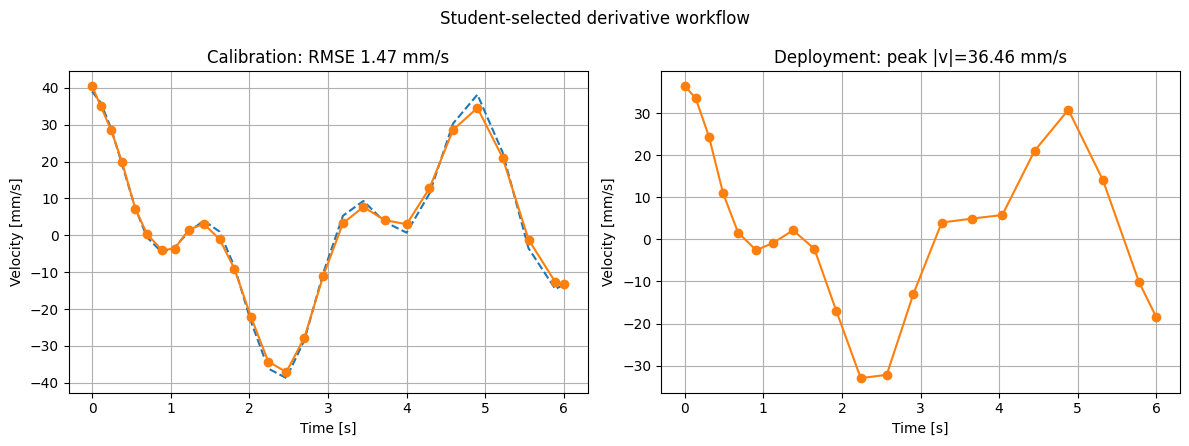

In [ ]:
time_cal_1b = np.array([0.00,0.11,0.24,0.38,0.55,0.70,0.89,1.05,1.23,1.42,1.62,1.81,2.02,2.24,2.47,2.70,2.94,3.19,3.45,3.72,4.00,4.29,4.59,4.90,5.22,5.55,5.89,6.00])
noise_cal_1b = 0.00018*np.sin(23*time_cal_1b+0.3)
position_cal_1b = actuator_position_m(time_cal_1b)+noise_cal_1b
reference_velocity_cal_1b = actuator_velocity_m_s(time_cal_1b)
time_deploy_1b = np.array([0.00,0.14,0.31,0.49,0.68,0.91,1.13,1.38,1.65,1.93,2.24,2.57,2.91,3.27,3.65,4.04,4.45,4.88,5.32,5.78,6.00])
position_deploy_1b = actuator_position_m(time_deploy_1b)+0.00018*np.sin(23*time_deploy_1b+1.0)


def derivative_candidate_1b(times, positions, method):
    if method == "gradient":
        return np.gradient(positions, times, edge_order=2)
    if method.startswith("local_fit_"):
        window = int(method.split("_")[-1])
        result = np.empty_like(positions)
        half = window//2
        for i, centre in enumerate(times):
            left = max(0, min(i-half, len(times)-window))
            indices = slice(left, left+window)
            shifted = times[indices]-centre
            coefficients = np.polyfit(shifted, positions[indices], 3)
            result[i] = coefficients[-2]
        return result
    raise ValueError("unknown derivative candidate")


candidate_methods_1b = ["gradient", "local_fit_5", "local_fit_9", "local_fit_13"]
rows_1b = []
for method in candidate_methods_1b:
    estimate = derivative_candidate_1b(time_cal_1b, position_cal_1b, method)
    rmse_mm_s = 1000*np.sqrt(np.mean((estimate-reference_velocity_cal_1b)**2))
    rows_1b.append({"method": method, "window_samples": 0 if method=="gradient" else int(method.split("_")[-1]),
                    "calibration_RMSE_mm_s": rmse_mm_s, "meets_requirement": rmse_mm_s <= 1.4})
candidates_1b = pd.DataFrame(rows_1b)
display(candidates_1b)


def plot_derivative_choice_1b(method, title):
    cal_velocity = derivative_candidate_1b(time_cal_1b, position_cal_1b, method)
    deploy_velocity = derivative_candidate_1b(time_deploy_1b, position_deploy_1b, method)
    row = candidates_1b[candidates_1b["method"]==method].iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(time_cal_1b, 1000*reference_velocity_cal_1b, "--", label="Reference velocity")
    axes[0].plot(time_cal_1b, 1000*cal_velocity, "o-", label="Estimated velocity")
    axes[0].set(xlabel="Time [s]", ylabel="Velocity [mm/s]", title=f"Calibration: RMSE {row['calibration_RMSE_mm_s']:.2f} mm/s")
    axes[1].plot(time_deploy_1b, 1000*deploy_velocity, "o-", color="tab:orange")
    axes[1].set(xlabel="Time [s]", ylabel="Velocity [mm/s]", title=f"Deployment: peak |v|={1000*np.max(np.abs(deploy_velocity)):.2f} mm/s")
    for ax in axes: ax.grid(True)
    fig.suptitle(title); fig.tight_layout(); plt.show()
    return deploy_velocity


selected_method_1b = "gradient"  # TODO: replace with a defensible candidate
student_velocity_1b = plot_derivative_choice_1b(selected_method_1b, "Student-selected derivative workflow")


**Your answer:** report the method, calibration RMSE, deployment peak speed with units, and
one limitation of transferring the calibration evidence to a new run.


## Activity 2B — Calibrate and validate a thermal ODE

**Problem:** estimate heat capacity $C$ and loss coefficient $H$ from irregular temperature
measurements in a heating experiment. Then validate the same parameters on a cooling
experiment with a different initial temperature and heater power. Do not refit on the
validation experiment.

**Hints:**

1. The residual vector must compare model and measured temperatures at the same times.
2. Both parameters must remain positive; bounds are supplied.
3. Try more than one initial guess to check that the optimiser reaches the same result.
4. Training fit alone is insufficient evidence of predictive usefulness.


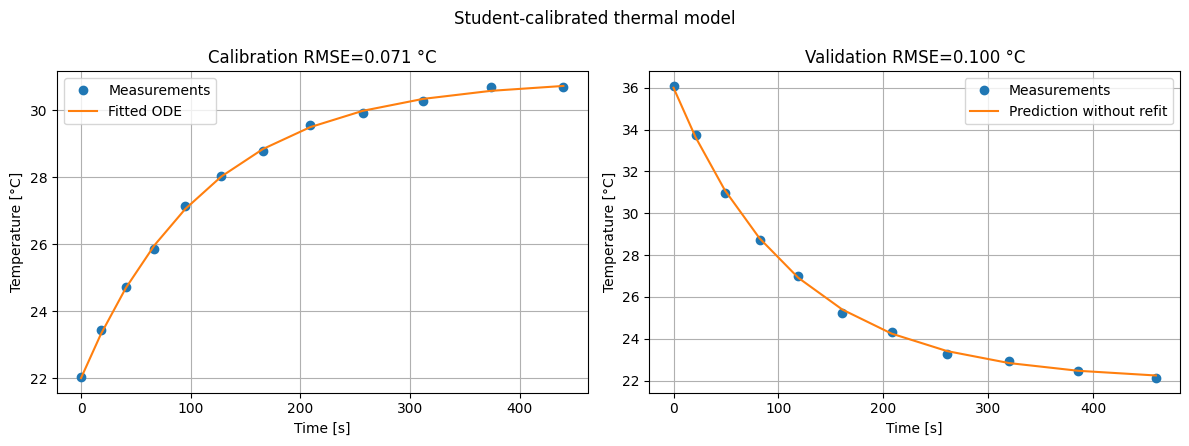

Estimated C=611.853 J/K, H=5.383 W/K


In [ ]:
TRUE_C_2B, TRUE_H_2B = 610.0, 5.4
train_time_2b = np.array([0,18,41,67,95,128,166,209,257,312,374,440], dtype=float)
train_temperature_2b = exact_thermal_temperature(train_time_2b, 22.0, TRUE_C_2B, TRUE_H_2B, heater_W=48.0)
train_temperature_2b += 0.12*np.sin(0.071*train_time_2b+0.2)
valid_time_2b = np.array([0,21,49,82,119,161,208,261,320,386,460], dtype=float)
valid_temperature_2b = exact_thermal_temperature(valid_time_2b, 36.0, TRUE_C_2B, TRUE_H_2B, heater_W=0.0)
valid_temperature_2b += 0.12*np.sin(0.063*valid_time_2b+0.8)


def thermal_residuals_2b(parameters):
    capacity, loss = parameters
    prediction = exact_thermal_temperature(train_time_2b, 22.0, capacity, loss, heater_W=48.0)
    return prediction-train_temperature_2b


def fit_thermal_model_2b(initial_guess):
    return least_squares(thermal_residuals_2b, initial_guess, bounds=([100,0.5],[2500,20]))


def plot_thermal_fit_2b(parameters, title):
    capacity, loss = parameters
    train_prediction = exact_thermal_temperature(train_time_2b, 22.0, capacity, loss, heater_W=48.0)
    valid_prediction = exact_thermal_temperature(valid_time_2b, 36.0, capacity, loss, heater_W=0.0)
    train_rmse = np.sqrt(np.mean((train_prediction-train_temperature_2b)**2))
    valid_rmse = np.sqrt(np.mean((valid_prediction-valid_temperature_2b)**2))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(train_time_2b, train_temperature_2b, "o", label="Measurements")
    axes[0].plot(train_time_2b, train_prediction, "-", label="Fitted ODE")
    axes[0].set(title=f"Calibration RMSE={train_rmse:.3f} °C", xlabel="Time [s]", ylabel="Temperature [°C]")
    axes[1].plot(valid_time_2b, valid_temperature_2b, "o", label="Measurements")
    axes[1].plot(valid_time_2b, valid_prediction, "-", label="Prediction without refit")
    axes[1].set(title=f"Validation RMSE={valid_rmse:.3f} °C", xlabel="Time [s]", ylabel="Temperature [°C]")
    for ax in axes: ax.grid(True); ax.legend()
    fig.suptitle(title); fig.tight_layout(); plt.show()
    return train_rmse, valid_rmse


selected_initial_guess_2b = [300.0, 12.0]  # TODO: try at least three defensible positive guesses
student_fit_2b = fit_thermal_model_2b(selected_initial_guess_2b)
student_metrics_2b = plot_thermal_fit_2b(student_fit_2b.x, "Student-calibrated thermal model")
print(f"Estimated C={student_fit_2b.x[0]:.3f} J/K, H={student_fit_2b.x[1]:.3f} W/K")


**Your answer:** report $C$, $H$, both RMSE values, initial-guess sensitivity, and one
experiment that would provide stronger parameter-identification evidence.


## Activity 3B — Select an Euler time step

**Problem:** choose the largest supplied Euler step that is linearly stable and keeps the
maximum temperature error at or below `0.20 °C` over 600 seconds. Using the largest valid
step minimises the number of right-hand-side evaluations among the supplied choices.

**Hints:**

1. A stable row can still fail the accuracy requirement.
2. Filter using both Boolean columns.
3. Sort eligible rows by evaluation count.
4. The analytical solution is available here to verify the teaching model.


,step_s,evaluations,amplification,stable,max_error_C,accurate
0,5,120,0.956731,True,0.081059,True
1,10,60,0.913462,True,0.165163,True
2,20,30,0.826923,True,0.342635,False
3,30,20,0.740385,True,0.535092,False
4,40,15,0.653846,True,0.744700,False
5,60,10,0.480769,True,1.228598,False
6,90,7,0.221154,True,2.180340,False
7,120,5,-0.038462,True,3.924604,False
8,180,4,-0.557692,True,5.711333,False
9,260,3,-1.250000,False,9.079173,False


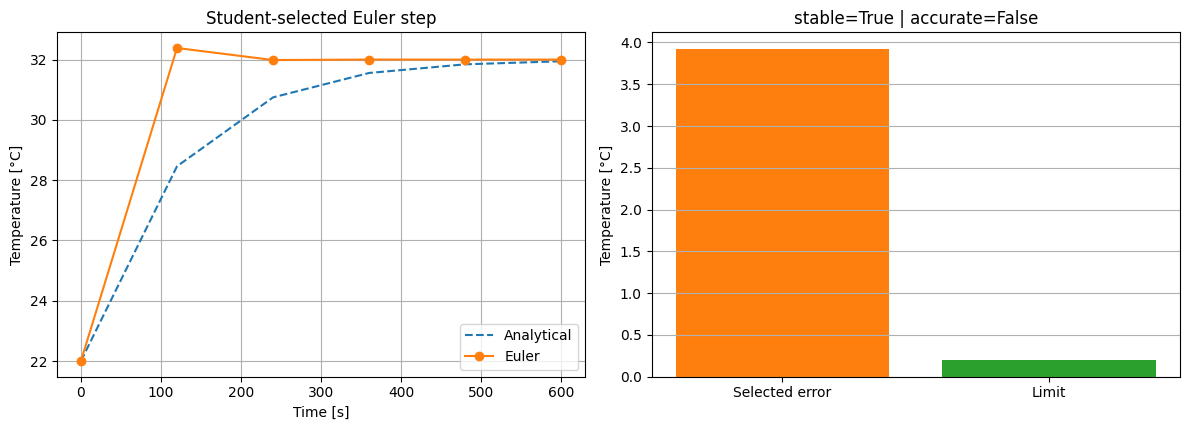

In [ ]:
candidate_steps_3b = [5,10,20,30,40,60,90,120,180,260]
C_3b, H_3b = 520.0, 4.5
rhs_3b = lambda t, T: thermal_rhs(t, T, C_3b, H_3b)
rows_3b = []
solutions_3b = {}
for step in candidate_steps_3b:
    times, values, evaluations = fixed_step_scalar(rhs_3b, (0,600), 22.0, step, "euler")
    exact = exact_thermal_temperature(times, 22.0, C_3b, H_3b)
    error = np.max(np.abs(values-exact))
    amplification = 1-step*H_3b/C_3b
    rows_3b.append({"step_s":step, "evaluations":evaluations, "amplification":amplification,
                    "stable":abs(amplification)<1, "max_error_C":error, "accurate":error<=0.20})
    solutions_3b[step] = (times, values, exact)
candidates_3b = pd.DataFrame(rows_3b)
display(candidates_3b)


def plot_euler_choice_3b(step, title):
    row = candidates_3b[candidates_3b["step_s"]==step].iloc[0]
    times, values, exact = solutions_3b[step]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    axes[0].plot(times, exact, "--", label="Analytical")
    axes[0].plot(times, values, "o-", label="Euler")
    axes[0].set(xlabel="Time [s]", ylabel="Temperature [°C]", title=title)
    axes[0].grid(True); axes[0].legend()
    axes[1].bar(["Selected error", "Limit"], [row["max_error_C"],0.20], color=["tab:orange","tab:green"])
    axes[1].set(ylabel="Temperature [°C]", title=f"stable={row['stable']} | accurate={row['accurate']}")
    axes[1].grid(True, axis="y"); fig.tight_layout(); plt.show()


selected_step_3b = 120  # TODO: replace with the least expensive valid step
plot_euler_choice_3b(selected_step_3b, "Student-selected Euler step")


**Your answer:** report the step, evaluation count, amplification factor and maximum error.
Explain why stability alone would allow a weaker answer.


## Activity 4B — Select a solver under an evaluation budget

**Problem:** choose the supplied method/setting with maximum error at or below `0.010 °C`
and no more than `80` right-hand-side evaluations. Among eligible candidates, select the
one with the fewest evaluations, then use error to break a tie.

**Hints:**

1. Compare achieved error—not formal order alone.
2. Fixed-step methods have different evaluations per step.
3. For RK45, `nfev` counts adaptive right-hand-side evaluations; `t_eval` does not force
   the solver to step at every output time.
4. Filter by both requirements before sorting by cost.


,candidate,method,setting,evaluations,max_error_C,error_ok,budget_ok
0,euler_h15,euler,h=15 s,40,2.522754e-01,False,True
1,euler_h30,euler,h=30 s,20,5.350921e-01,False,True
2,euler_h60,euler,h=60 s,10,1.228598e+00,False,True
3,euler_h120,euler,h=120 s,5,3.924604e+00,False,True
4,rk2_h15,rk2,h=15 s,80,1.139909e-02,False,True
5,rk2_h30,rk2,h=30 s,40,5.050279e-02,False,True
6,rk2_h60,rk2,h=60 s,20,2.492697e-01,False,True
7,rk2_h120,rk2,h=120 s,10,1.467408e+00,False,True
8,rk4_h15,rk4,h=15 s,160,9.693137e-06,True,False
9,rk4_h30,rk4,h=30 s,80,1.728960e-04,True,True


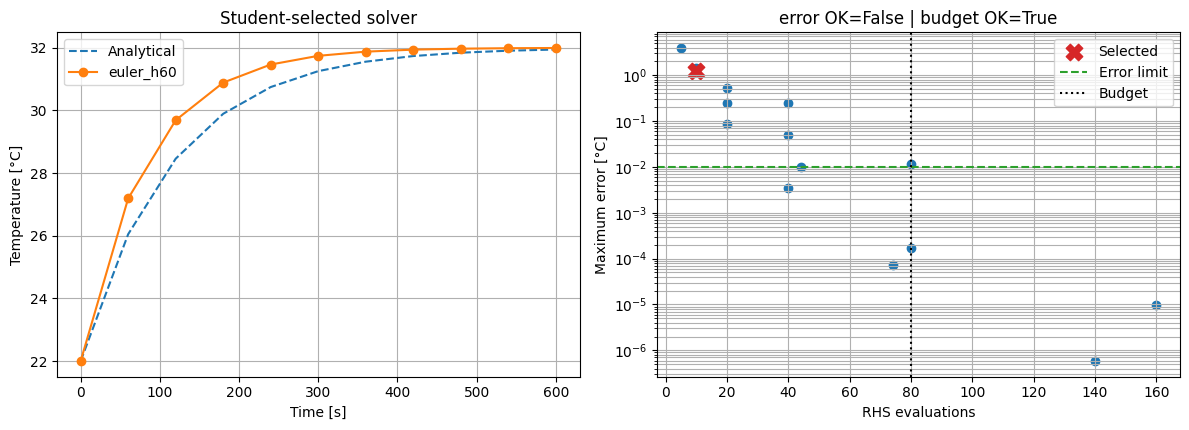

In [ ]:
C_4b, H_4b = 520.0, 4.5
rhs_4b = lambda t, T: thermal_rhs(t, T, C_4b, H_4b)
candidates_4b = []
stored_4b = {}
for method in ["euler","rk2","rk4"]:
    for step in [15,30,60,120]:
        times, values, evaluations = fixed_step_scalar(rhs_4b, (0,600), 22.0, step, method)
        exact = exact_thermal_temperature(times, 22.0, C_4b, H_4b)
        error = np.max(np.abs(values-exact))
        name = f"{method}_h{step}"
        candidates_4b.append({"candidate":name,"method":method,"setting":f"h={step} s",
                              "evaluations":evaluations,"max_error_C":error,
                              "error_ok":error<=0.010,"budget_ok":evaluations<=80})
        stored_4b[name] = (times,values,exact)
output_times_4b = np.linspace(0,600,121)
for tolerance in [1e-3,1e-5,1e-7]:
    sol = solve_ivp(lambda t,y: rhs_4b(t,y[0]), (0,600), [22.0], t_eval=output_times_4b,
                    rtol=tolerance, atol=tolerance*0.01)
    exact = exact_thermal_temperature(output_times_4b, 22.0, C_4b, H_4b)
    error = np.max(np.abs(sol.y[0]-exact))
    name = f"rk45_rtol{tolerance:g}"
    candidates_4b.append({"candidate":name,"method":"rk45","setting":f"rtol={tolerance:g}",
                          "evaluations":sol.nfev,"max_error_C":error,
                          "error_ok":error<=0.010,"budget_ok":sol.nfev<=80})
    stored_4b[name] = (output_times_4b,sol.y[0],exact)
table_4b = pd.DataFrame(candidates_4b)
display(table_4b)


def plot_solver_choice_4b(candidate, title):
    row = table_4b[table_4b["candidate"]==candidate].iloc[0]
    times, values, exact = stored_4b[candidate]
    fig, axes = plt.subplots(1, 2, figsize=(12,4.4))
    axes[0].plot(times, exact, "--", label="Analytical")
    axes[0].plot(times, values, "o-", markevery=max(1,len(times)//12), label=candidate)
    axes[0].set(xlabel="Time [s]",ylabel="Temperature [°C]",title=title)
    axes[0].grid(True); axes[0].legend()
    axes[1].scatter(table_4b["evaluations"],table_4b["max_error_C"])
    axes[1].scatter(row["evaluations"],row["max_error_C"],marker="X",s=140,color="tab:red",label="Selected")
    axes[1].axhline(0.010,linestyle="--",color="tab:green",label="Error limit")
    axes[1].axvline(80,linestyle=":",color="black",label="Budget")
    axes[1].set_yscale("log"); axes[1].set(xlabel="RHS evaluations",ylabel="Maximum error [°C]",
                                            title=f"error OK={row['error_ok']} | budget OK={row['budget_ok']}")
    axes[1].grid(True,which="both"); axes[1].legend(); fig.tight_layout(); plt.show()


selected_candidate_4b = "euler_h60"  # TODO: replace after filtering and sorting
plot_solver_choice_4b(selected_candidate_4b, "Student-selected solver")


**Your answer:** report the candidate, method setting, error and evaluations. Explain why
output sample count and adaptive solver step count are not the same quantity.


## Activity 5B — Select and validate a vibration model

**Problem:** displacement measurements are available for a freely vibrating test article.
Compare three model structures, all fitted only to the calibration run:

- `"undamped"`: assumes $c=0$ and fits $k$;
- `"known_stiffness"`: uses independently known $k=200$ N/m and fits $c$; and
- `"fit_c_and_k"`: fits both $c$ and $k$.

Select the simplest model with validation RMSE at or below `0.60 mm`. Validation uses a new
initial state and no refitting.

**Hints:**

1. Position is measured; velocity remains a model state.
2. Compare calibration and validation, not calibration alone.
3. Filter by the validation requirement, then prefer fewer fitted parameters.
4. Inspect residual pattern as well as one RMSE number.


,model,fitted_parameters,c_Ns_m,k_N_m,training_RMSE_mm,validation_RMSE_mm,valid
0,undamped,1,0.000000,178.817530,27.551934,20.313511,False
1,known_stiffness,1,7.995239,200.000000,0.317732,0.320125,True
2,fit_c_and_k,2,8.002481,200.186301,0.317420,0.320685,True


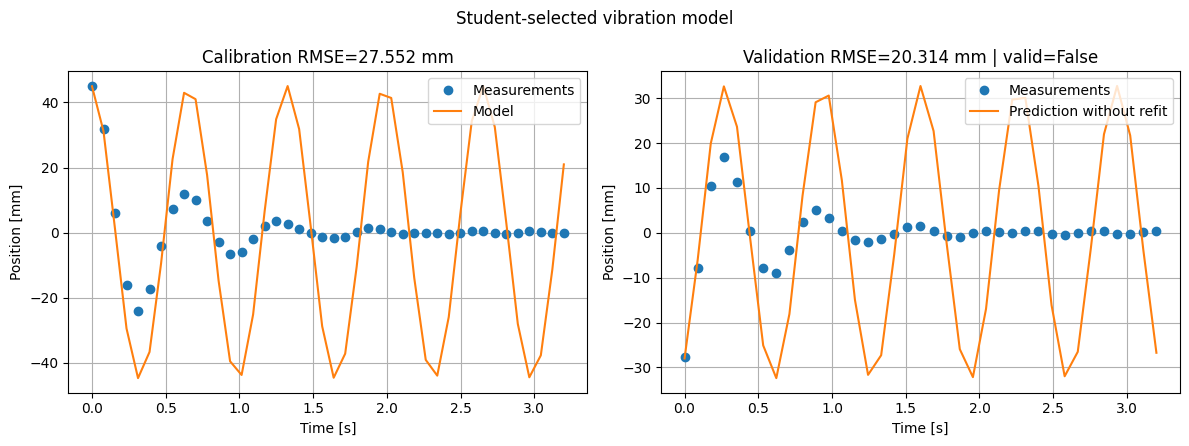

In [ ]:
MASS_5B, TRUE_C_5B, TRUE_K_5B = 2.0, 8.0, 200.0
train_time_5b = np.linspace(0,3.2,42)
valid_time_5b = np.linspace(0,3.2,37)


def simulate_position_5b(times, initial_state, damping, stiffness):
    sol = solve_ivp(lambda t,y: oscillator_rhs(t,y,MASS_5B,damping,stiffness),
                    (times[0],times[-1]),initial_state,t_eval=times,rtol=2e-9,atol=[1e-11,1e-10])
    return sol.y[0]


measured_train_5b = simulate_position_5b(train_time_5b,[0.045,-0.03],TRUE_C_5B,TRUE_K_5B)
measured_train_5b += 0.00045*np.sin(17.3*train_time_5b+0.2)
measured_valid_5b = simulate_position_5b(valid_time_5b,[-0.028,0.16],TRUE_C_5B,TRUE_K_5B)
measured_valid_5b += 0.00045*np.sin(16.1*valid_time_5b+0.8)


def fit_model_5b(model_name):
    if model_name == "undamped":
        result = least_squares(lambda p: simulate_position_5b(train_time_5b,[0.045,-0.03],0.0,p[0])-measured_train_5b,
                               [170],bounds=([80],[350]))
        return 0.0,result.x[0],1
    if model_name == "known_stiffness":
        result = least_squares(lambda p: simulate_position_5b(train_time_5b,[0.045,-0.03],p[0],200.0)-measured_train_5b,
                               [4],bounds=([0],[30]))
        return result.x[0],200.0,1
    if model_name == "fit_c_and_k":
        result = least_squares(lambda p: simulate_position_5b(train_time_5b,[0.045,-0.03],p[0],p[1])-measured_train_5b,
                               [4,170],bounds=([0,80],[30,350]))
        return result.x[0],result.x[1],2
    raise ValueError("unknown model")


model_names_5b = ["undamped","known_stiffness","fit_c_and_k"]
model_results_5b = {}
rows_5b = []
for name in model_names_5b:
    damping,stiffness,parameter_count = fit_model_5b(name)
    train_prediction = simulate_position_5b(train_time_5b,[0.045,-0.03],damping,stiffness)
    valid_prediction = simulate_position_5b(valid_time_5b,[-0.028,0.16],damping,stiffness)
    train_rmse = 1000*np.sqrt(np.mean((train_prediction-measured_train_5b)**2))
    valid_rmse = 1000*np.sqrt(np.mean((valid_prediction-measured_valid_5b)**2))
    rows_5b.append({"model":name,"fitted_parameters":parameter_count,"c_Ns_m":damping,"k_N_m":stiffness,
                    "training_RMSE_mm":train_rmse,"validation_RMSE_mm":valid_rmse,"valid":valid_rmse<=0.60})
    model_results_5b[name]=(train_prediction,valid_prediction)
table_5b = pd.DataFrame(rows_5b)
display(table_5b)


def plot_vibration_choice_5b(model_name,title):
    row = table_5b[table_5b["model"]==model_name].iloc[0]
    train_prediction,valid_prediction=model_results_5b[model_name]
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    axes[0].plot(train_time_5b,1000*measured_train_5b,"o",label="Measurements")
    axes[0].plot(train_time_5b,1000*train_prediction,label="Model")
    axes[0].set(title=f"Calibration RMSE={row['training_RMSE_mm']:.3f} mm",xlabel="Time [s]",ylabel="Position [mm]")
    axes[1].plot(valid_time_5b,1000*measured_valid_5b,"o",label="Measurements")
    axes[1].plot(valid_time_5b,1000*valid_prediction,label="Prediction without refit")
    axes[1].set(title=f"Validation RMSE={row['validation_RMSE_mm']:.3f} mm | valid={row['valid']}",xlabel="Time [s]",ylabel="Position [mm]")
    for ax in axes: ax.grid(True); ax.legend()
    fig.suptitle(title); fig.tight_layout(); plt.show()


selected_model_5b = "undamped"  # TODO: replace with the simplest valid model
plot_vibration_choice_5b(selected_model_5b,"Student-selected vibration model")


**Your answer:** report the model, fitted parameters with units, calibration and validation
RMSE, and why unmeasured velocity can still appear in the state equations.


# ⬛ Revision and home study

Finish incomplete B activities before attempting the questions below. Answers should use
units, numerical evidence and physical interpretation—not only method names.


## 📝 Activity 6 — Test-style short problems

1. Position is sampled every 0.02 s. State the units of its first finite difference divided by 0.02 s.
2. Why is `np.gradient(position)` unsafe when the time spacing is not 1 s?
3. Give one reason a centred difference cannot be used unchanged at the first sample.
4. Explain why differentiating noisy displacement twice is usually more fragile than fitting a dynamic model.
5. In $C\dot{T}=P-H(T-T_a)$, identify the state, input and two parameters.
6. Distinguish an ODE parameter from an initial condition using the thermal model.
7. Why should calibrated parameters be tested on a different experiment without refitting?
8. Write one Euler update for $\dot y=f(t,y)$.
9. If halving Euler's step approximately halves global error, state the observed order.
10. Explain why a stable Euler solution can still be too inaccurate for an engineering decision.
11. How many right-hand-side evaluations does one classical RK4 step require?
12. Distinguish `t_eval` output times from adaptive RK45 internal steps.
13. Convert $m\ddot{x}+c\dot{x}+kx=F(t)$ into two first-order equations using $v=\dot{x}$.
14. In `state=[x,v]`, does `state[1]` mean the second experiment, sample, or physical state component?


## 🧪 Activity 7 — Integrated method-selection challenge

For each scenario, choose a starting workflow and one validation check:

1. velocity from irregular, noisy displacement measurements;
2. a known smooth scalar ODE needing a quick transparent hand calculation;
3. a non-stiff ODE requiring reliable output at irregular measurement times;
4. identification of heat capacity and loss coefficient from temperature experiments;
5. acceleration of a vibrating body when only noisy displacement is measured;
6. a second-order rotational equation with angular position and angular velocity states.

State what information is measured, assumed, fitted and numerically calculated.


# 🔗 Project bridge

Choose one dynamic quantity in a proposed project dataset and write an eight-line plan:

1. engineering question and decision;
2. measured samples, coordinates and units;
3. proposed state variables;
4. known inputs and boundary or initial conditions;
5. parameters to assume or calibrate;
6. derivative or ODE method and why it matches the available data;
7. numerical and physical validation checks; and
8. evidence that would make you reject the result.


# ✅ Week 7 completion checklist

- [ ] I changed and explained every guided `TODO` in Activities 1A–5A.
- [ ] I completed and justified every problem in Activities 1B–5B.
- [ ] I preserved physical coordinates and units when differentiating data.
- [ ] I can distinguish samples, states, initial conditions, parameters and solver steps.
- [ ] I can explain Euler stability separately from accuracy.
- [ ] I can compare ODE methods using achieved error and right-hand-side evaluations.
- [ ] I can convert a second-order ODE into a first-order state system.
- [ ] I used independent validation rather than reporting calibration fit alone.
- [ ] I completed Activities 6–7 without copying a solution.


# 📚 References and data provenance

Method definitions and APIs follow the official NumPy and SciPy documentation referenced
in Notes 7.1–7.5. All actuator, thermal and vibration examples are synthetic,
deterministic and generated in code. They expose numerical behaviour and are not
measurements for engineering design.

# 🤖 AI acknowledgement

Generative AI assisted with drafting, code development and editorial review. Activities,
numerical behaviour and tutor solutions were checked for alignment with the Week 7 notes
and unit learning outcomes.
